# 01 - Grape production: load, clean, explore

Turns the raw ISTAT extract into a clean annual production series for Piedmont
(regional total and per-province) and explores it. No external data or API key is
needed for this notebook.

In [1]:
# Install dependencies once (uncomment to run):
# !pip install -q -r requirements.txt

In [2]:
# Locate the project root and make src/ + config importable.
import os, sys
d = os.getcwd()
while not os.path.exists(os.path.join(d, "config.py")) and os.path.dirname(d) != d:
    d = os.path.dirname(d)
os.chdir(d)
if d not in sys.path:
    sys.path.insert(0, d)
print("Project root:", d)

Project root: /Users/shreyshukla/Documents/ICS Project


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import config
from src import production
pd.set_option('display.width', 120)

## 1. The source file has a mislabelled header

In the raw CSV the column headings are shifted one place: the column labelled
`Year` holds the crop name, and `Crop` holds the year. `production.load_raw_istat`
corrects this, but it is worth seeing first-hand.

In [4]:
raw_uncorrected = pd.read_csv(config.ISTAT_CSV)
print('Columns as labelled:', list(raw_uncorrected.columns))
raw_uncorrected.head(3)

Columns as labelled: ['Region_code', 'Region_name', 'Year', 'Crop', 'Observation', 'Amount', 'Area', 'Yield']


,Region_code,Region_name,Year,Crop,Observation,Amount,Area,Yield
0,ITC2,"'Valle d""'Aosta / Vallée d""'Aoste'",WINEES,2006,35000,530,66.037736,NaN
1,ITC2,"'Valle d""'Aosta / Vallée d""'Aoste'",WINEES,2007,25000,690,36.231884,NaN
2,ITC2,"'Valle d""'Aosta / Vallée d""'Aoste'",WINEES,2008,25000,539,46.382189,NaN


In [5]:
# Row 0, field by field: 'Year' holds 'WINEES' (crop) and 'Crop' holds 2006 (year).
raw_uncorrected.iloc[0]

Region_code                                  ITC2
Region_name    'Valle d"'Aosta / Vallée d"'Aoste'
Year                                       WINEES
Crop                                         2006
Observation                                 35000
Amount                                        530
Area                                    66.037736
Yield                                         NaN
Name: 0, dtype: object

## 2. Load with corrected columns

In [6]:
df = production.load_raw_istat()
print('Corrected columns:', list(df.columns))
df.head(3)

Corrected columns: ['region_code', 'region_name', 'crop', 'year', 'production', 'area_ha', 'yield_per_ha']


,region_code,region_name,crop,year,production,area_ha,yield_per_ha
0,ITC2,"'Valle d""'Aosta / Vallée d""'Aoste'",WINEES,2006,35000,530,66.037736
1,ITC2,"'Valle d""'Aosta / Vallée d""'Aoste'",WINEES,2007,25000,690,36.231884
2,ITC2,"'Valle d""'Aosta / Vallée d""'Aoste'",WINEES,2008,25000,539,46.382189


## 3. Build the Piedmont series

Piedmont is the sum of 7 NUTS-3 provinces (Torino is absent from the extract).
Production and area are summed; yield is recomputed from the regional totals.

In [7]:
piedmont = production.build_piedmont_series(df)
piedmont

,region,year,production,area_ha,yield_per_ha,n_provinces
0,Piedmont,2006,4329387,50226,86.198124,7
1,Piedmont,2007,3761763,50256,74.852018,7
2,Piedmont,2008,3486550,50812,68.616665,7
3,Piedmont,2009,3908621,50573,77.286714,7
4,Piedmont,2010,4002303,46824,85.475461,7
5,Piedmont,2011,3547509,50582,70.133822,7
6,Piedmont,2012,3173365,44883,70.703050,7
7,Piedmont,2013,3607148,47737,75.562939,7
8,Piedmont,2014,3332383,42379,78.632884,7
9,Piedmont,2015,3436998,41756,82.311476,7


In [8]:
# Persist for later notebooks.
piedmont.to_csv(config.PRODUCTION_CSV, index=False)
print('saved ->', config.PRODUCTION_CSV)

saved -> /Users/shreyshukla/Documents/ICS Project/data/processed/piedmont_production.csv


## 4. Exploratory data analysis

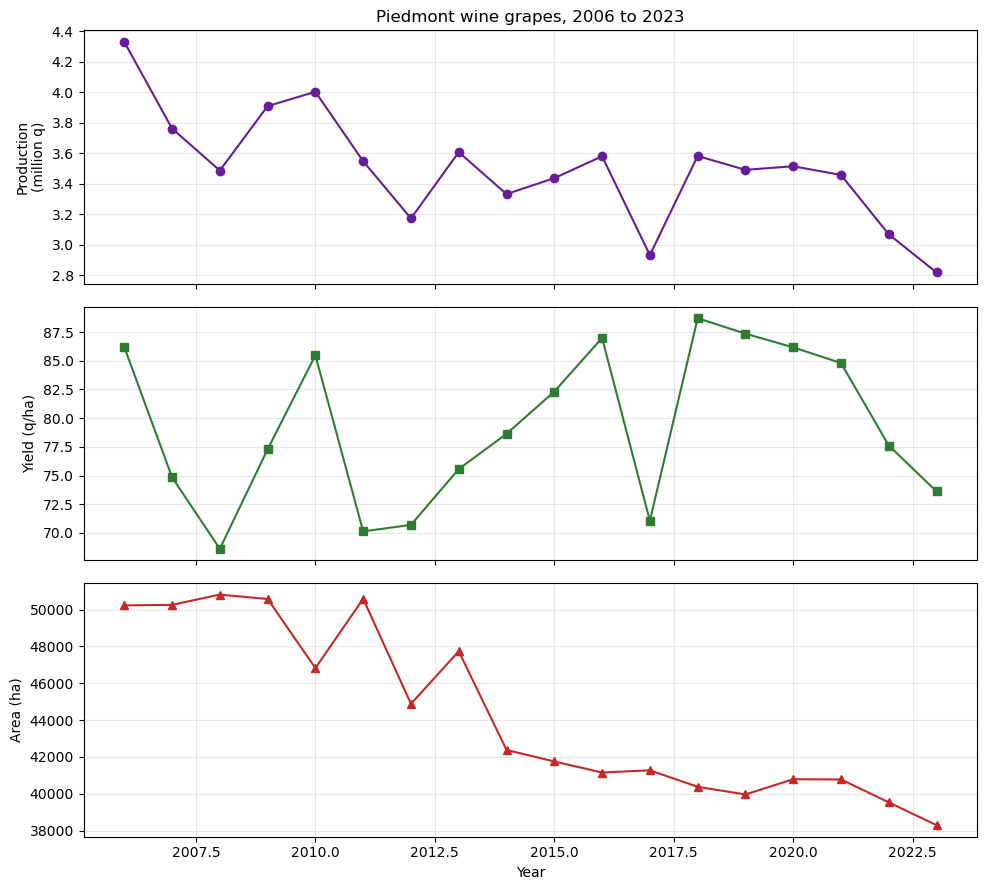

In [9]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax[0].plot(piedmont.year, piedmont.production/1e6, marker='o', color='#6a1b9a'); ax[0].set_ylabel('Production\n(million q)')
ax[1].plot(piedmont.year, piedmont.yield_per_ha, marker='s', color='#2e7d32'); ax[1].set_ylabel('Yield (q/ha)')
ax[2].plot(piedmont.year, piedmont.area_ha, marker='^', color='#c62828'); ax[2].set_ylabel('Area (ha)'); ax[2].set_xlabel('Year')
for a in ax: a.grid(alpha=.3)
ax[0].set_title('Piedmont wine grapes, 2006 to 2023')
plt.tight_layout(); plt.show()

Two points shape the rest of the analysis:

- Vineyard area declines (about 50k to 38k ha), a structural trend unrelated to
  weather. The climate analysis therefore works with yield per hectare, and
  detrends it, to isolate the weather signal.
- 2017 is the weakest year in the record, a known heat, drought and frost vintage
  in Italy, so a climate signal is plausibly present.

In [10]:
print('Yield summary (q/ha):'); print(piedmont.yield_per_ha.describe().round(1))
print('\nLowest-yield years:'); print(piedmont.nsmallest(3, 'yield_per_ha')[['year','yield_per_ha','production']].to_string(index=False))

Yield summary (q/ha):
count    18.0
mean     79.2
std       6.9
min      68.6
25%      73.9
50%      78.1
75%      86.0
max      88.7
Name: yield_per_ha, dtype: float64

Lowest-yield years:
 year  yield_per_ha  production
 2008     68.616665     3486550
 2011     70.133822     3547509
 2012     70.703050     3173365


Output: `data/processed/piedmont_production.csv` and
`..._by_province.csv`. Next, `02_climate_data.ipynb` builds the climate indices.